# Task 3: Predictive Customer Churn Classifier
## Random Forest & XGBoost | Datheon Machine Learning & Data Science Internship

**Objective:** Predict whether a telecommunications customer will churn, compare Random Forest and XGBoost, and optimize ROC-AUC while reporting accuracy, precision, recall and F1-score.

**Dataset:** The supplied Telco Customer Churn CSV is loaded from the project folder. This notebook does not require an internet connection.

### Learning outcomes
- Inspect and clean a real-world customer dataset.
- Convert `TotalCharges` to numeric and impute missing values without leakage.
- Encode categorical features inside model pipelines.
- Train and tune Random Forest and XGBoost models with stratified cross-validation.
- Evaluate once on a held-out test set and interpret the results.
- Review permutation importance and explore an out-of-fold decision threshold.

> **Evaluation note:** The target ROC-AUC of 0.80 is a goal, not a guarantee. Hyperparameters and the decision threshold are selected using training data only; the held-out test set is reserved for final evaluation. Scores are measured results, not promises of future performance.


## 1. Install and import libraries

Run the installation cell if any package is missing. In VS Code, select the Python environment/kernel where these packages are installed.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


The imports completed successfully, so the notebook has the dependencies needed for plotting, preprocessing, model training, cross-validation, evaluation, and saving artifacts. The fixed random seed makes the split and randomized search reproducible.

**Observed result:** `Libraries imported successfully.`


## 2. Load the Telco Customer Churn dataset

The supplied CSV is loaded from the project folder. Keep `Task 3-Telco-Customer-Churn.csv` beside this notebook, or update `DATA_PATH` if it is stored elsewhere.

In [2]:
DATA_PATH = Path("Task 3-Telco-Customer-Churn.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place the CSV beside this notebook or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded from: /Users/mac/Desktop/Internship/Task 3-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The CSV was read from the project folder without needing a network download. The preview confirms the expected customer attributes and `Churn` target are present.

**Observed result:** 7,043 rows and 21 columns were loaded. The dataset includes the expected `customerID` and `TotalCharges` fields.


## 3. Initial data inspection

Inspect column types, missing values, duplicates, and the target distribution before making changes.

In [3]:
df.info()
display(df.describe(include="all").T)
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0

Missing values by column:


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


The schema inspection shows a mix of numeric and categorical fields. `TotalCharges` is initially stored as text, so it must be parsed before modelling. The duplicate and missing-value summaries help determine the required cleaning steps; blank charge strings are not counted as pandas nulls until conversion.

**Observed result:** 7,043 records are available; no duplicate rows or pandas-recognized null values were found in the raw CSV.


Target counts:


,count
Churn,
No,5174
Yes,1869



Target proportions:


,percentage
Churn,
No,73.46
Yes,26.54


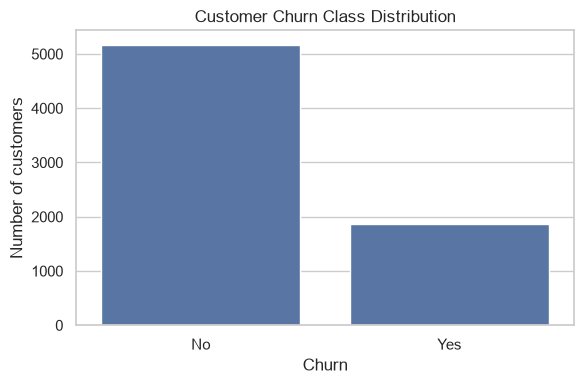

In [4]:
TARGET = "Churn"
if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found.")

print("Target counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))
print("\nTarget proportions:")
display((df[TARGET].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percentage"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


The target is imbalanced: most customers did not churn. Accuracy alone could therefore conceal poor detection of churners, which is why the notebook also reports ROC-AUC, precision, recall, and F1-score. **Observed result:** 5,174 customers did not churn (73.46%) and 1,869 churned (26.54%). The bar chart visualizes this class imbalance.


## 4. Data cleaning

`customerID` is an identifier, not a predictive measurement, so it is excluded. In this dataset, `TotalCharges` may contain blank strings for customers with very short tenure. Convert it to numeric with invalid values coerced to missing; the numeric imputer in the modelling pipeline will handle those values using the training data only.

In [5]:
data = df.drop_duplicates().copy()

if "TotalCharges" in data.columns:
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

data[TARGET] = data[TARGET].astype("string").str.strip()
target_map = {"No": 0, "Yes": 1}
unexpected_targets = set(data[TARGET].dropna().unique()) - set(target_map)
if unexpected_targets:
    raise ValueError(f"Unexpected target labels: {unexpected_targets}")

data[TARGET] = data[TARGET].map(target_map)
data = data.dropna(subset=[TARGET])

if "customerID" in data.columns:
    data = data.drop(columns=["customerID"])

X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int)

print("Cleaned feature matrix:", X.shape)
print("Target distribution:")
display(y.value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("count"))
print("Missing TotalCharges:", int(X["TotalCharges"].isna().sum()) if "TotalCharges" in X.columns else "Column absent")


Cleaned feature matrix: (7043, 19)
Target distribution:


,count
Churn,
No churn,5174
Churn,1869


Missing TotalCharges: 11


The customer identifier is removed because it is not a meaningful customer-behavior measurement. `TotalCharges` is converted to numeric, and missing values are left for the training-fold imputer so they are not filled using test data. The target is mapped to 0/1 for classification. **Observed result:** all 7,043 rows remain, with 19 predictors; 5,174 non-churn and 1,869 churn labels; 11 `TotalCharges` values require imputation.


## 5. Exploratory data analysis

Explore churn rates across a few important customer characteristics. These are descriptive comparisons, not evidence of causation.

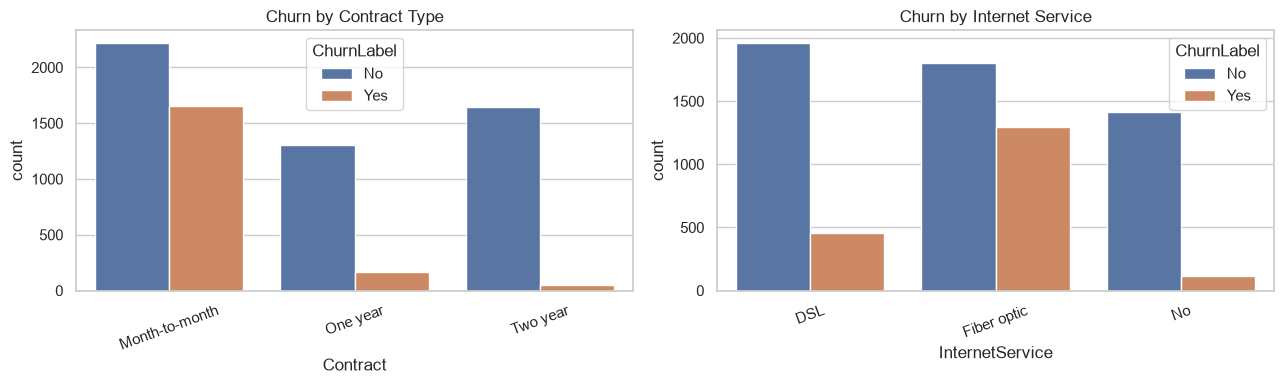

In [6]:
eda = data.copy()
eda["ChurnLabel"] = eda[TARGET].map({0: "No", 1: "Yes"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=eda, x="Contract", hue="ChurnLabel", ax=axes[0])
axes[0].set_title("Churn by Contract Type")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=eda, x="InternetService", hue="ChurnLabel", ax=axes[1])
axes[1].set_title("Churn by Internet Service")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


These plots compare churn counts by contract type and internet service. The underlying data shows much higher churn among month-to-month customers (42.7%) than one-year (11.3%) or two-year customers (2.8%). Churn is also higher for fiber-optic customers (41.9%) than DSL (19.0%) or customers without internet service (7.4%). These are associations in this dataset, not proof that a contract or service type causes churn.


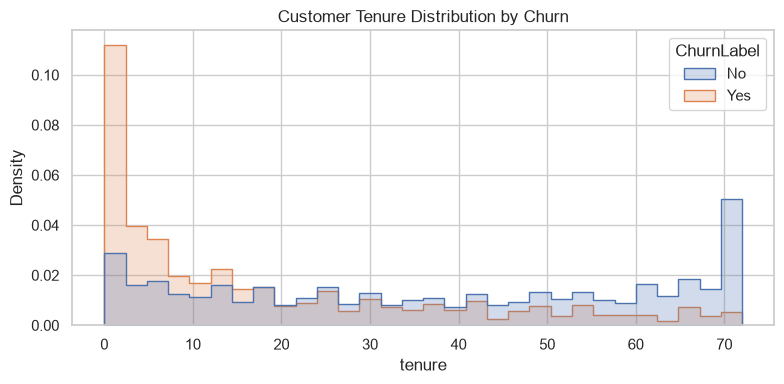

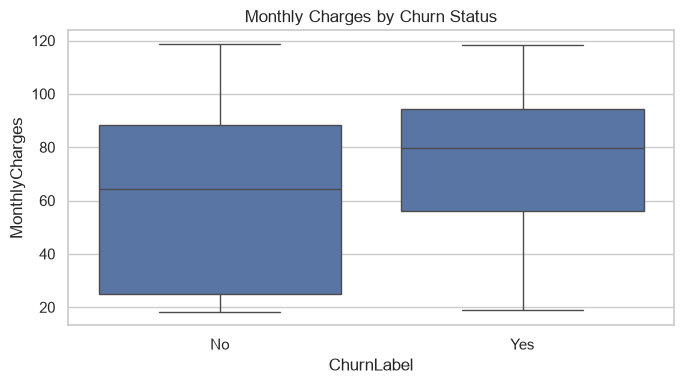

In [7]:
if "tenure" in data.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=eda, x="tenure", hue="ChurnLabel", bins=30,
                 element="step", stat="density", common_norm=False)
    plt.title("Customer Tenure Distribution by Churn")
    plt.tight_layout()
    plt.show()

if "MonthlyCharges" in data.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda, x="ChurnLabel", y="MonthlyCharges")
    plt.title("Monthly Charges by Churn Status")
    plt.tight_layout()
    plt.show()


The distributions show that churners tend to have shorter tenure and higher monthly charges in this dataset. **Observed summaries:** median tenure is 10 months for churners versus 38 months for non-churners; median monthly charges are 79.65 versus 64.43, respectively. These patterns help motivate the predictive analysis but are not causal findings.


## 6. Train/test split

Use a stratified split so the churn proportion is approximately preserved in both subsets. The test data is not used for fitting, cross-validation or hyperparameter selection.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training churn rate:", round(float(y_train.mean()), 4))
print("Testing churn rate:", round(float(y_test.mean()), 4))


Training rows: 5634
Testing rows: 1409
Training churn rate: 0.2654
Testing churn rate: 0.2654


A stratified 80/20 split preserves the churn proportion in both datasets. The test data is kept aside for final evaluation and is not used to fit preprocessing or select model parameters. **Observed result:** 5,634 training rows and 1,409 test rows; churn rate is 26.54% in both partitions after rounding.


## 7. Preprocessing pipeline

Numeric features are median-imputed and standardised. Categorical features are imputed with the most frequent value and one-hot encoded. `handle_unknown="ignore"` allows the model to handle categories that were not present during training.

The preprocessing transformer is placed inside each model pipeline. This ensures that imputers, scaling and category encoding are learned only from the training portion of each cross-validation fold.

In [9]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


The features are separated into numeric and categorical groups. Numeric values will be median-imputed and scaled; categories will be most-frequent-imputed and one-hot encoded. These transformations are included in each estimator pipeline, so cross-validation learns them from each fold's training portion only. **Observed result:** four numeric predictors and 15 categorical predictors were identified.


## 8. Address class imbalance

Churn is commonly the minority class. We will use class weighting rather than applying SMOTE to the one-hot encoded matrix. This avoids creating fractional values in categorical indicator columns and keeps the full preprocessing/model workflow straightforward.

- Random Forest: `class_weight="balanced"`.
- XGBoost: the search compares no class weighting (`scale_pos_weight=1`) with the training-only non-churn/churn ratio.

Class weighting changes the penalty assigned to errors; it does not change the actual class frequencies.

In [10]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("Non-churn training cases:", negative_count)
print("Churn training cases:", positive_count)
print("XGBoost scale_pos_weight:", round(scale_pos_weight, 3))


Non-churn training cases: 4139
Churn training cases: 1495
XGBoost scale_pos_weight: 2.769


The training data contains substantially more non-churn than churn cases. The computed ratio is supplied as one candidate XGBoost class weight during tuning; the search is also allowed to choose no weighting. The Random Forest uses balanced subsample weights. **Observed result:** 4,139 non-churn and 1,495 churn training cases; the ratio is approximately 2.769.


## 9. Build Random Forest and XGBoost models

Both models use the same preprocessing and training/test split. `n_jobs=-1` allows scikit-learn and XGBoost to use available CPU resources; if your Mac becomes unresponsive, reduce the number of estimators or set `n_jobs=2`.

In [11]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=2,
        tree_method="hist"
    ))
])

print("Leakage-safe Random Forest and XGBoost pipelines created.")


Leakage-safe Random Forest and XGBoost pipelines created.


Both classifiers now include the same leakage-safe preprocessing. XGBoost uses histogram-based tree growth to make training more efficient, while model-specific settings are optimized later using the training partition. **Observed result:** both model pipelines were created successfully.


## 10. Stratified cross-validation

Use five-fold stratified cross-validation on the training data. ROC-AUC is the primary selection metric; the other metrics provide additional context. Each fold fits its own preprocessing steps.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []
for model_name, estimator in [
    ("Random Forest baseline", rf_pipeline),
    ("XGBoost baseline", xgb_pipeline)
]:
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    row = {"Model": model_name}
    for metric in scoring:
        row[f"{metric.upper()} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric.upper()} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(4))


,ROC_AUC mean,ROC_AUC std,ACCURACY mean,ACCURACY std,PRECISION mean,PRECISION std,RECALL mean,RECALL std,F1 mean,F1 std
Model,,,,,,,,,,
Random Forest baseline,0.8192,0.0133,0.7833,0.0093,0.6248,0.0263,0.4602,0.0178,0.5298,0.0188
XGBoost baseline,0.8229,0.0084,0.7842,0.0132,0.6137,0.0323,0.5057,0.0212,0.5544,0.0246


Five-fold stratified cross-validation provides a repeatable baseline before parameter search. The displayed means and standard deviations summarize the training folds; they are not final test scores. **Observed result:** baseline mean ROC-AUC was 0.8192 for Random Forest and 0.8229 for XGBoost. Both cross-validation means exceed the task's 0.80 ROC-AUC goal, with XGBoost slightly higher in this baseline comparison.


## 11. Hyperparameter tuning

Randomized search compares a reproducible set of model configurations using training data only. The scoring objective is ROC-AUC; the held-out test set is reserved for final evaluation.

In [13]:
rf_search_space = {
    "model__n_estimators": [300, 500, 700],
    "model__max_depth": [None, 8, 12, 16, 24],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_search_space,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=0,
    refit=True
)
rf_search.fit(X_train, y_train)

print("Best Random Forest training CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Best parameters:", rf_search.best_params_)


Best Random Forest training CV ROC-AUC: 0.8473
Best parameters: {'model__n_estimators': 500, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8}


Randomized search compares a fixed set of Random Forest configurations using five-fold ROC-AUC on training data. The selected parameters are based on cross-validation only, so the test set remains untouched. **Observed result:** the best training CV ROC-AUC was 0.8473, using 500 trees, maximum depth 8, minimum split size 10, minimum leaf size 4, and square-root feature sampling.


In [14]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

xgb_search_space = {
    "model__n_estimators": [250, 400, 600, 800],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.015, 0.03, 0.05, 0.08, 0.1],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__reg_lambda": [1, 2, 5, 10],
    "model__scale_pos_weight": [1.0, scale_pos_weight]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_search_space,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=0,
    refit=True
)
xgb_search.fit(X_train, y_train)

print("Best XGBoost training CV ROC-AUC:", round(xgb_search.best_score_, 4))
print("Best parameters:", xgb_search.best_params_)


Best XGBoost training CV ROC-AUC: 0.8504
Best parameters: {'model__subsample': 0.7, 'model__scale_pos_weight': 1.0, 'model__reg_lambda': 10, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.015, 'model__colsample_bytree': 0.85}


This search tests tree depth, learning rate, sampling, regularization, and alternative class-weight settings. It selects configurations using only the training folds. **Observed result:** the best training CV ROC-AUC was 0.8504. The selected configuration uses 600 trees, depth 3, learning rate 0.015, subsample 0.70, column subsampling 0.85, regularization 10, and `scale_pos_weight=1.0`. It narrowly exceeds the tuned Random Forest CV score.


## 12. Final evaluation on the untouched test set

The best estimator from each training-only search is evaluated once on the held-out test set. The final model is selected using cross-validation ROC-AUC, not the test results. ROC-AUC uses predicted probabilities and does not depend on a single classification threshold. The confusion matrix and classification report use the default 0.50 threshold; threshold adjustment can be considered later based on business costs.

In [15]:
best_models = {
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_
}

cv_auc_scores = {
    "Random Forest": rf_search.best_score_,
    "XGBoost": xgb_search.best_score_
}
selected_name = max(cv_auc_scores, key=cv_auc_scores.get)

# The test set is used once for final evaluation, never for model selection.
evaluation_rows = []
test_probabilities = {}
test_predictions = {}

for name, model in best_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    test_probabilities[name] = probabilities
    test_predictions[name] = predictions

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Training CV ROC-AUC": cv_auc_scores[name]
    })

test_results = pd.DataFrame(evaluation_rows).set_index("Model")
display(test_results.round(4))
print("Model selected using training CV ROC-AUC:", selected_name)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training CV ROC-AUC
Model,,,,,,
Random Forest,0.7580,0.5298,0.7834,0.6321,0.843,0.8473
XGBoost,0.8048,0.6689,0.5241,0.5877,0.849,0.8504


Model selected using training CV ROC-AUC: XGBoost


Each tuned model is evaluated on the test data at the common 0.50 threshold. ROC-AUC uses probabilities and measures ranking quality; the threshold-based metrics show the classification trade-offs. Model selection is based on training CV ROC-AUC, not these test results. **Observed result:** XGBoost was selected by CV (0.8504 versus 0.8473). On the test set, XGBoost achieved ROC-AUC 0.8490 and accuracy 0.8048; Random Forest achieved ROC-AUC 0.8430 and accuracy 0.7580. Random Forest has higher churn recall at 0.50 (0.7834 versus 0.5241), while XGBoost has higher precision (0.6689 versus 0.5298).


In [16]:
for name in best_models:
    print("\\n", "=" * 65)
    print(name)
    print("=" * 65)
    print(classification_report(
        y_test, test_predictions[name],
        target_names=["No churn", "Churn"],
        zero_division=0
    ))


\n =================================================================
Random Forest
              precision    recall  f1-score   support

    No churn       0.91      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409

\n =================================================================
XGBoost
              precision    recall  f1-score   support

    No churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



The reports break performance down by the actual class. At threshold 0.50, XGBoost catches fewer churners but makes fewer false churn predictions than Random Forest. This illustrates why model choice and decision threshold should reflect retention capacity and the cost of missed churn. **Observed result:** XGBoost churn precision/recall/F1 are 0.67/0.52/0.59; Random Forest churn precision/recall/F1 are 0.53/0.78/0.63. Overall test accuracy is approximately 0.80 for XGBoost and 0.76 for Random Forest.


## 13. ROC curves

The ROC curve plots the true-positive rate against the false-positive rate across possible thresholds. A curve closer to the upper-left corner generally indicates better discrimination. The diagonal represents random ranking.

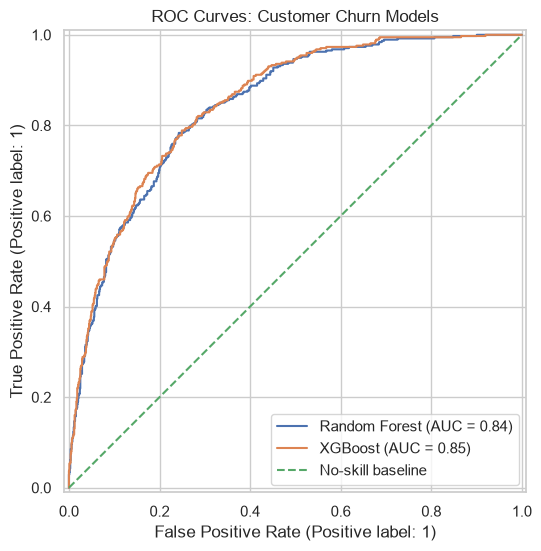

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, probabilities, name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="No-skill baseline")
ax.set_title("ROC Curves: Customer Churn Models")
ax.legend()
plt.show()


The plot compares the models' true-positive and false-positive rates over a range of thresholds. Curves above the diagonal indicate better-than-random ranking. The curves are consistent with the numeric test ROC-AUC values reported in the next cell; small differences should not be over-interpreted as proof of a large performance gap.


In [18]:
for name, probabilities in test_probabilities.items():
    auc_value = roc_auc_score(y_test, probabilities)
    status = "Met the 0.80 target" if auc_value >= 0.80 else "Below the 0.80 target"
    print(f"{name}: test ROC-AUC = {auc_value:.4f} — {status}")


Random Forest: test ROC-AUC = 0.8430 — Met the 0.80 target
XGBoost: test ROC-AUC = 0.8490 — Met the 0.80 target


This cell compares each test ROC-AUC with the stated 0.80 goal. ROC-AUC is threshold-independent and is the notebook's primary model-selection measure **Observed result:** Random Forest test ROC-AUC is 0.8430 and XGBoost test ROC-AUC is 0.8490. Both meet the 0.80 goal; XGBoost is slightly higher.


## 14. Confusion matrices

A confusion matrix shows true negatives, false positives, false negatives and true positives. In churn prediction, false negatives are customers who churn but were predicted to stay; false positives are customers predicted to churn who actually stay.

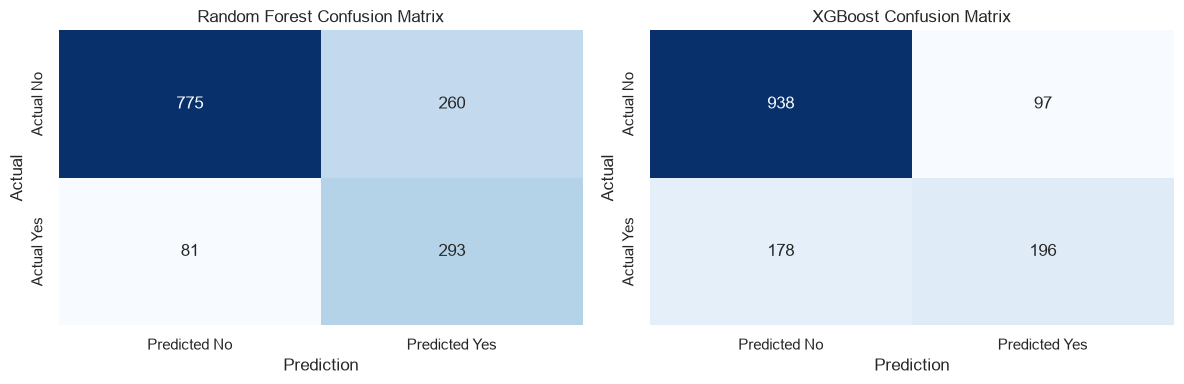

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"]
    )
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


Rows show actual classes and columns show predictions at threshold 0.50. In the order `[[true negatives, false positives], [false negatives, true positives]]`, Random Forest produced `[[775, 260], [81, 293]]`; XGBoost produced `[[938, 97], [178, 196]]`. Random Forest identifies more churners, while XGBoost has fewer false-positive churn alerts.


## 15. Feature importance: top 10 predictors

Permutation importance is used on the held-out test data. It measures the drop in ROC-AUC when one feature is shuffled, and works with the original input columns even though the model internally one-hot encodes categories. Importance is model-dependent and should not be interpreted as causation.

,Feature,Importance,Std
0,Contract,0.074026,0.005645
1,tenure,0.046234,0.002427
2,InternetService,0.008807,0.004001
3,TotalCharges,0.007542,0.001636
4,MonthlyCharges,0.007246,0.002771
5,OnlineSecurity,0.005775,0.001306
6,TechSupport,0.003663,0.001412
7,PaymentMethod,0.002881,0.001160
8,PaperlessBilling,0.002881,0.001617
9,MultipleLines,0.002564,0.001470


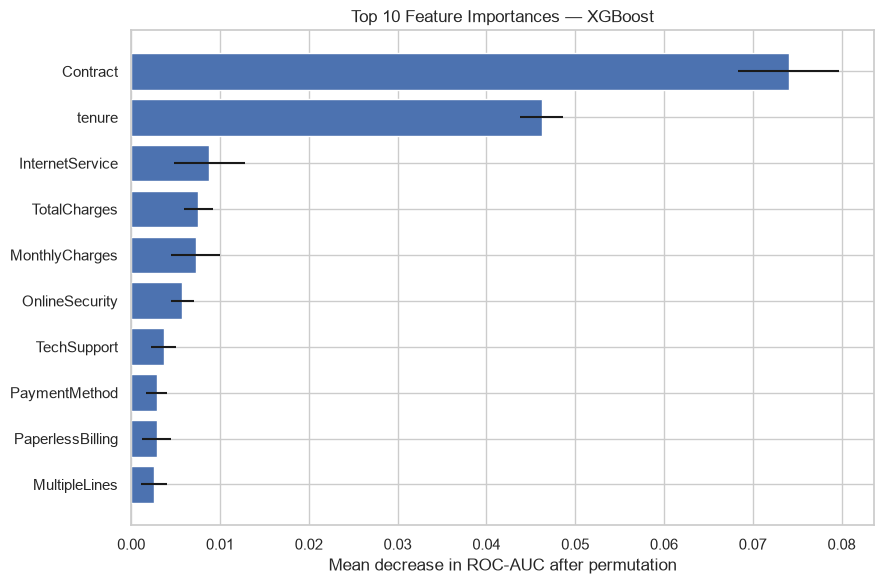

In [20]:
# Select the feature-importance model using training-only CV results.
selected_model = best_models[selected_name]

perm = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

top10 = importance.head(10).sort_values("Importance")
display(top10.sort_values("Importance", ascending=False).reset_index(drop=True))

plt.figure(figsize=(9, 6))
plt.barh(top10["Feature"], top10["Importance"], xerr=top10["Std"])
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title(f"Top 10 Feature Importances — {selected_name}")
plt.tight_layout()
plt.show()


A feature's importance is the decrease in test ROC-AUC when its values are shuffled. Larger positive values indicate that the selected model relies more on that feature for ranking customers. Importance is predictive association, not causation. **Observed result:** `Contract` is the strongest feature (mean AUC decrease about 0.074), followed by `tenure` (about 0.046). `InternetService`, `TotalCharges`, and `MonthlyCharges` follow at a much smaller level. Because the test set is used here only for post-fit explanation, these values are descriptive and are not used to select or refit the model.


## 16. Optional: examine alternative classification thresholds

A threshold of 0.50 is not always the best business choice. Lowering it may identify more customers at risk (higher recall) but can also increase false positives. Use the table below as a diagnostic; choose a threshold based on the cost of retention offers and the cost of missing a customer who churns.

,Threshold,Accuracy,Precision,Recall,F1
0,0.20,0.722,0.486,0.860,0.621
1,0.25,0.747,0.515,0.818,0.632
2,0.30,0.768,0.544,0.769,0.637
3,0.35,0.785,0.578,0.705,0.635
4,0.40,0.799,0.615,0.646,0.630
5,0.45,0.805,0.646,0.591,0.617
6,0.50,0.808,0.673,0.536,0.597
7,0.55,0.802,0.689,0.463,0.554
8,0.60,0.797,0.715,0.390,0.505
9,0.65,0.792,0.748,0.324,0.453


Training out-of-fold F1-selected threshold: 0.30
Out-of-fold F1 at selected threshold: 0.6373
Threshold metrics are training-only estimates; final test metrics above remain at threshold 0.50.


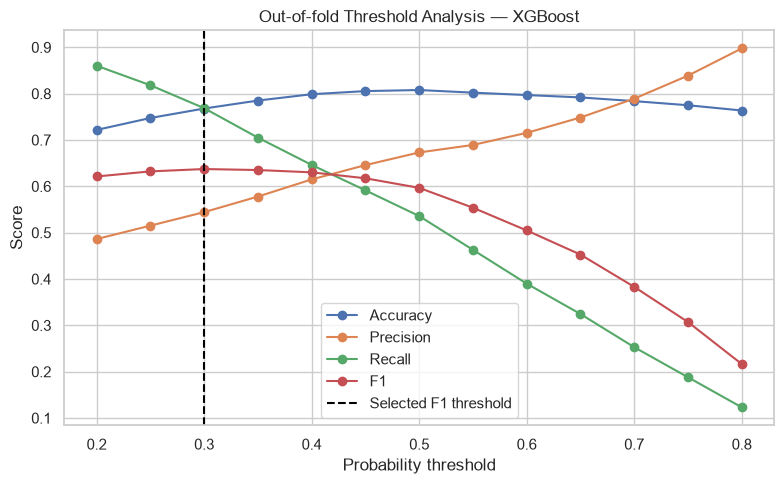

In [21]:
# Estimate a decision threshold from out-of-fold training probabilities, not from test labels.
oof_probabilities = cross_val_predict(
    selected_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_train, pred),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[threshold_results["F1"].idxmax()]
selected_threshold = float(best_threshold_row["Threshold"])
display(threshold_results.round(3))
print(f"Training out-of-fold F1-selected threshold: {selected_threshold:.2f}")
print(f"Out-of-fold F1 at selected threshold: {best_threshold_row['F1']:.4f}")
print("Threshold metrics are training-only estimates; final test metrics above remain at threshold 0.50.")

plt.figure(figsize=(8, 5))
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    plt.plot(threshold_results["Threshold"], threshold_results[metric], marker="o", label=metric)
plt.axvline(selected_threshold, color="black", linestyle="--", label="Selected F1 threshold")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title(f"Out-of-fold Threshold Analysis — {selected_name}")
plt.legend()
plt.tight_layout()
plt.show()


This cell estimates threshold performance from out-of-fold training probabilities, avoiding the use of held-out test labels to choose a threshold. The F1-maximizing threshold is a candidate operating point that prioritizes a balance between precision and recall; it is not a universal business optimum. **Observed result:** the selected training-only threshold is 0.30. Its out-of-fold estimates are approximately 0.768 accuracy, 0.544 precision, 0.769 recall, and 0.637 F1. Compared with 0.50, it catches more churners but is expected to create more false-positive outreach. The final test metrics above remain at 0.50.


## 17. Save the best model and evaluation artefacts

Save the selected fitted pipeline (including preprocessing) so new raw customer records can be passed directly to `predict_proba`. The model file is created in the notebook's current working directory.

In [22]:
best_model_name = selected_name
final_model = best_models[best_model_name]

joblib.dump(final_model, "customer_churn_best_model.joblib")
test_results.to_csv("customer_churn_test_metrics.csv")
importance.to_csv("customer_churn_feature_importance.csv", index=False)

print("Model selected by training CV ROC-AUC:", best_model_name)
print("Training CV ROC-AUC:", round(cv_auc_scores[best_model_name], 4))
print("Saved fitted model and evaluation CSV files.")


Model selected by training CV ROC-AUC: XGBoost
Training CV ROC-AUC: 0.8504
Saved fitted model and evaluation CSV files.


The model saved is the one selected by training cross-validation ROC-AUC, not by comparing test scores. It includes preprocessing, so future records can be passed using the original predictor columns. The CSV files preserve the test metrics and permutation-importance results. **Observed result:** XGBoost was selected (training CV ROC-AUC 0.8504), and the model plus evaluation CSV files were saved in the project folder.


## 18. Interactive prediction helper

Enter customer details using the same raw column names and categories as the original dataset. The example below starts from a real test record to ensure the feature schema is valid. Change values to explore how the predicted churn probability changes.

In [23]:
def predict_churn(customer_record, fitted_model=final_model, threshold=selected_threshold):
    """Predict churn and return its estimated probability for new customer data."""
    if isinstance(customer_record, dict):
        customer_record = pd.DataFrame([customer_record])

    missing_cols = set(X.columns) - set(customer_record.columns)
    extra_cols = set(customer_record.columns) - set(X.columns)
    if missing_cols:
        raise ValueError(f"Missing required columns: {sorted(missing_cols)}")
    if extra_cols:
        raise ValueError(f"Unexpected columns: {sorted(extra_cols)}")

    customer_record = customer_record.loc[:, X.columns]
    probability = float(fitted_model.predict_proba(customer_record)[0, 1])
    prediction = int(probability >= threshold)

    return {
        "prediction": "Churn" if prediction == 1 else "No churn",
        "churn_probability": round(probability, 4),
        "decision_threshold": round(float(threshold), 2)
    }

example_customer = X_test.iloc[[0]].copy()
display(example_customer)
print(predict_churn(example_customer))


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


{'prediction': 'No churn', 'churn_probability': 0.0361, 'decision_threshold': 0.3}


The example is a held-out customer record passed through the saved pipeline and the threshold estimated from out-of-fold training predictions. **Observed result:** the example is predicted as `No churn`, with estimated churn probability 0.0361, below the 0.30 decision threshold. Its actual dataset label is also `No`; one matching example does not establish general model accuracy.


## 19. Final project summary

Run this cell after all previous cells. It prints the measured test-set results for the report. Do not manually insert expected scores; use the actual output from your execution.

In [24]:
best_model_name = selected_name
best_row = test_results.loc[best_model_name]

print("DATHEON TASK 3 — CUSTOMER CHURN CLASSIFICATION")
print("-" * 58)
print(f"Rows used: {len(data)} (train: {len(X_train)}, test: {len(X_test)})")
print("Models compared: tuned Random Forest and XGBoost")
print("Model selected using training CV ROC-AUC:", best_model_name)
print(f"Training CV ROC-AUC: {cv_auc_scores[best_model_name]:.4f}")
print(f"Held-out test ROC-AUC: {best_row['ROC-AUC']:.4f}")
print(f"Held-out test accuracy at threshold 0.50: {best_row['Accuracy']:.4f}")
print(f"Held-out test precision at threshold 0.50: {best_row['Precision']:.4f}")
print(f"Held-out test recall at threshold 0.50: {best_row['Recall']:.4f}")
print(f"Held-out test F1 at threshold 0.50: {best_row['F1-score']:.4f}")
print("ROC-AUC target (0.80):", "ACHIEVED" if best_row["ROC-AUC"] >= 0.80 else "NOT ACHIEVED")
print(f"Training out-of-fold F1 threshold for prediction helper: {selected_threshold:.2f}")


DATHEON TASK 3 — CUSTOMER CHURN CLASSIFICATION
----------------------------------------------------------
Rows used: 7043 (train: 5634, test: 1409)
Models compared: tuned Random Forest and XGBoost
Model selected using training CV ROC-AUC: XGBoost
Training CV ROC-AUC: 0.8504
Held-out test ROC-AUC: 0.8490
Held-out test accuracy at threshold 0.50: 0.8048
Held-out test precision at threshold 0.50: 0.6689
Held-out test recall at threshold 0.50: 0.5241
Held-out test F1 at threshold 0.50: 0.5877
ROC-AUC target (0.80): ACHIEVED
Training out-of-fold F1 threshold for prediction helper: 0.30


This cell compiles the final submission figures. It identifies the model using training-fold ROC-AUC and reports the held-out test metrics at threshold 0.50, alongside the separate training-only F1 threshold. **Observed result:** XGBoost was selected; training CV ROC-AUC is 0.8504, test ROC-AUC is 0.8490, and test accuracy is 0.8048. The 0.80 ROC-AUC target is achieved. Test precision is 0.6689, recall is 0.5241, and F1 is 0.5877 at threshold 0.50.


## 20. Conclusion and business recommendations

The supplied Telco dataset contains 7,043 customers, with 26.54% labeled as churners. After removing the identifier, converting `TotalCharges`, and fitting imputation and encoding only within training folds, tuned Random Forest and XGBoost models were compared using five-fold stratified cross-validation.

**XGBoost was selected using training CV ROC-AUC (0.8504).** On the untouched test set, it achieved ROC-AUC **0.8490** and accuracy **0.8048** at the default 0.50 threshold, meeting the stated ROC-AUC goal of 0.80. Test precision was 0.6689, recall 0.5241, and F1-score 0.5877. Random Forest achieved a slightly lower test ROC-AUC (0.8430) and accuracy (0.7580), but higher churn recall (0.7834) at 0.50. This demonstrates that accuracy/AUC alone do not decide which outreach strategy is best.

Out-of-fold training predictions selected a 0.30 threshold for F1, with estimated recall of 0.769 and F1 of 0.637. This is a training-only estimate and should be validated against operational costs before deployment. `Contract` and `tenure` had the largest permutation-importance values, indicating predictive association rather than causation.